# 🫀 Lab: Binary Classification with Logistic Regression
**CS316: Introduction to AI and Data Science**

## Scenario
You have just joined the data team of a **regional cardiology clinic**. Every week, hundreds of patients come in with chest-pain complaints, but the clinic has only a few slots per day for the (expensive) full cardiac work-up.

Your manager asks you to build a **triage assistant**: a model that, from routine measurements (age, blood pressure, cholesterol, ECG results, …), estimates **the probability that a patient has heart disease**, so the highest-risk patients are examined first.

Along the way you will practise everything from the lecture:

| Part | Topic | Slides |
|---|---|---|
| 1 | Exploring the heart-disease data | 2 |
| 2 | Target-variable encoding (label & one-hot) | 3–8 |
| 3 | Logistic regression: logit & sigmoid | 9–12 |
| 4 | Likelihood & log-likelihood | 13–15 |
| 5 | Preparing data, training & testing | 16–21 |
| 6 | Making predictions | 22–24 |
| 7 | Model evaluation (precision, recall, F1, confusion matrix) | 25–27 |
| 8 | Interpreting results | 28–30 |
| 9 | Limits of the classification report → ROC & AUC | 31–40 |

> ✍️ Cells marked **🧪 Your turn** contain a `# TODO` that you must complete. Run the cells **in order**.

## Part 0 — Setup

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, roc_auc_score, auc, log_loss)

pd.set_option("display.max_columns", 30)
plt.rcParams["figure.figsize"] = (6, 4)
RANDOM_STATE = 42

## Part 1 — The data: UCI Heart Disease (Cleveland)

Each row is a patient. The columns are:

| Column | Meaning |
|---|---|
| `age` | Age in years |
| `sex` | 1 = male, 0 = female |
| `cp` | Chest-pain type (1–4) |
| `trestbps` | Resting blood pressure (mm Hg) |
| `chol` | Serum cholesterol (mg/dl) |
| `fbs` | Fasting blood sugar > 120 mg/dl (1 = true, 0 = false) |
| `restecg` | Resting ECG result (0, 1, 2) |
| `thalach` | Maximum heart rate achieved |
| `exang` | Exercise-induced angina (1 = yes, 0 = no) |
| `oldpeak` | ST depression induced by exercise relative to rest |
| `slope` | Slope of the peak-exercise ST segment |
| `ca` | Number of major vessels (0–3) coloured by fluoroscopy |
| `thal` | 3 = normal, 6 = fixed defect, 7 = reversible defect |
| **`num`** | **Diagnosis**: 0 = no disease, 1–4 = degree of disease |

In [ ]:
URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"
COLS = ["age","sex","cp","trestbps","chol","fbs","restecg","thalach",
        "exang","oldpeak","slope","ca","thal","num"]

def make_backup_data(n=303, seed=0):
    """Offline fallback: synthetic data with the same columns (ONLY used if the download fails)."""
    r = np.random.default_rng(seed)
    d = pd.DataFrame({
        "age": r.integers(29, 78, n), "sex": r.integers(0, 2, n), "cp": r.integers(1, 5, n),
        "trestbps": r.normal(131, 17, n).round(), "chol": r.normal(246, 51, n).round(),
        "fbs": r.integers(0, 2, n), "restecg": r.choice([0, 1, 2], n),
        "thalach": r.normal(149, 23, n).round(), "exang": r.integers(0, 2, n),
        "oldpeak": np.clip(r.gamma(1.2, 0.9, n), 0, 6).round(1), "slope": r.integers(1, 4, n),
        "ca": r.choice([0.0, 1.0, 2.0, 3.0], n, p=[.6, .2, .12, .08]),
        "thal": r.choice([3.0, 6.0, 7.0], n, p=[.55, .06, .39])})
    z = (-3 + .03*(d.age-54) + .8*d.sex + .6*(d.cp == 4) - .03*(d.thalach-150) + .9*d.exang
         + .6*d.oldpeak + .8*d.ca + .9*(d.thal == 7))
    d["num"] = (r.random(n) < 1/(1+np.exp(-z))).astype(int)
    return d

try:
    df = pd.read_csv(URL, header=None, names=COLS, na_values="?")
    print("✅ Real UCI dataset loaded.")
except Exception as e:
    df = make_backup_data()
    print("⚠️ Download failed -> using SYNTHETIC backup data (results will differ from the slides).")

print(df.shape)
df.head()

✅ Real UCI dataset loaded.
(303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [ ]:
df.info()
print("\nMissing values per column:")
print(df.isna().sum()[df.isna().sum() > 0])

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB

Missing values per column:
ca      4
thal    2
dtype: int64


**Q1.** How many patients are in the dataset? Which columns have missing values?

*(Note: `ca` and `thal` have a few missing entries. We will not delete those rows — we will see later that one-hot encoding handles them as their own category, exactly like the `ca_nan` / `thal_nan` columns on the slides.)*

In [ ]:
df["num"].value_counts().sort_index()

,count
num,
0,164
1,55
2,36
3,35
4,13


## Part 2 — Target variable encoding

The model needs a **binary** target. The original column `num` is 0 (no disease) or 1–4 (disease of increasing severity).
For **binary classification** we collapse it into a text label `Target ∈ {NO, YES}`, as in the lecture, and then convert it to numbers.

In [ ]:
df["Target"] = np.where(df["num"] > 0, "YES", "NO")
df[["num", "Target"]].head(8)

,num,Target
0,0,NO
1,2,YES
2,1,YES
3,0,NO
4,0,NO
5,0,NO
6,3,YES
7,0,NO


Target
NO     164
YES    139
Name: count, dtype: int64


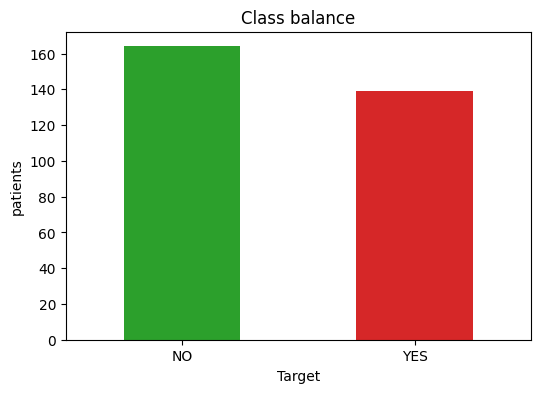

In [ ]:
counts = df["Target"].value_counts()
print(counts)
counts.plot(kind="bar", color=["tab:green", "tab:red"], rot=0, title="Class balance")
plt.ylabel("patients"); plt.show()
# Balanced dataset

### 2.1 Label encoding
Map each category to an integer: **NO → 0**, **YES → 1**

$$\text{Target}_{encoded}=\begin{cases}0 & \text{if Target = NO}\\ 1 & \text{if Target = YES}\end{cases}$$

In [ ]:
demo = pd.DataFrame({"Target": ["NO", "YES", "YES", "NO"]})
demo["Target_encoded"] = demo["Target"].astype("category").cat.codes
demo

,Target,Target_encoded
0,NO,0
1,YES,1
2,YES,1
3,NO,0


> ⚠️ `astype('category').cat.codes` assigns codes **alphabetically** (NO=0, YES=1). That is fine for 2 classes, but it **introduces an order** that may not exist when there are more than two categories — which is why we also need one-hot encoding.

### 2.2 One-hot encoding
Each category becomes its own 0/1 column using the indicator function $\mathbb{1}_{category}(x)$:

$$\text{Target}_{NO}=\mathbb{1}_{NO}(\text{Target}),\qquad \text{Target}_{YES}=\mathbb{1}_{YES}(\text{Target})$$

**With scikit-learn:**

In [ ]:
encoder = OneHotEncoder(sparse_output=False) # Creates an encoder - sparse output = false returns regular numpy array explicitly storing every value, including zeros
enc = encoder.fit_transform(demo[["Target"]]) # discovers categories, creates their columns and converts their values
demo_sk = pd.concat([demo[["Target"]],
                     pd.DataFrame(enc, columns=encoder.get_feature_names_out(["Target"]))], axis=1)
demo_sk # Retrieve the names of the output columns during encoding - gives col names so we know what each represents

,Target,Target_NO,Target_YES
0,NO,1.0,0.0
1,YES,0.0,1.0
2,YES,0.0,1.0
3,NO,1.0,0.0


**With pandas** (simpler, ideal for quick exploration):

In [ ]:
pd.get_dummies(demo, columns=["Target"], prefix="Target", dtype=int)# prefix-how it will rename

,Target_encoded,Target_NO,Target_YES
0,0,1,0
1,1,0,1
2,1,0,1
3,0,1,0


**🧪 Your turn 2.1** — Encode the **real** target column of `df` in two ways:
1. a new column `Target_encoded` with label encoding,
2. one-hot columns using `pd.get_dummies`, stored in `target_onehot`.

Then check that `Target_encoded` equals the one-hot column `Target_YES`.

In [ ]:
# TODO 1: label encoding
df["Target_encoded"] = df['Target'].astype('category').cat.codes        # <-- complete

# TODO 2: one-hot encoding (keep only the new columns)
target_onehot = pd.get_dummies(df,prefix="Target", dtype=int)                   # <-- complete (hint: pd.get_dummies(df["Target"], prefix="Target", dtype=int))
# Check
print((df["Target_encoded"] == target_onehot["Target_YES"]).all())
target_onehot

# 2 ways to implement one hot encoder -> through scikit learn package or pandas

True


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num,Target_encoded,Target_NO,Target_YES
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0,0,1,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2,1,0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1,1,0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0,0,1,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,45.0,1.0,1.0,110.0,264.0,0.0,0.0,132.0,0.0,1.2,2.0,0.0,7.0,1,1,0,1
299,68.0,1.0,4.0,144.0,193.0,1.0,0.0,141.0,0.0,3.4,2.0,2.0,7.0,2,1,0,1
300,57.0,1.0,4.0,130.0,131.0,0.0,0.0,115.0,1.0,1.2,2.0,1.0,7.0,3,1,0,1
301,57.0,0.0,2.0,130.0,236.0,0.0,2.0,174.0,0.0,0.0,2.0,1.0,3.0,1,1,0,1


**Q2.** For a *binary* target, why is one-hot encoding redundant (what is the relationship between `Target_NO` and `Target_YES`)? When would one-hot encoding of the target be really needed?

## Part 3 — Logistic regression: logit and sigmoid

A linear combination of the features gives a score

$$z=\beta_0+\beta_1x_1+\dots+\beta_nx_n$$

which can be any real number. The **sigmoid** squeezes it into a probability:

$$\sigma(z)=\frac{1}{1+e^{-z}}=P(Y=1\mid X)$$

and its inverse, the **logit** (log-odds), brings us back:

$$\text{logit}(p)=\ln\!\left(\frac{p}{1-p}\right)=z$$

In [ ]:
# Maximize the likelihood -> probability in order to reduce the error = minimizing the loss in the linear regression

def sigmoid(z):
    return 1 / (1 + np.exp(-z)) # converts unrestricted score into valid probability


def logit(p):
    return np.log(p / (1 - p)) # given probability p, what score corresponds to it

z = np.linspace(-8, 8, 200)
p = np.linspace(0.001, 0.999, 200)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(z, sigmoid(z)); ax[0].axhline(0.5, ls="--", c="gray"); ax[0].axvline(0, ls="--", c="gray")
ax[0].set(title="Sigmoid: score z → probability", xlabel="z", ylabel="σ(z)")
ax[1].plot(p, logit(p), c="tab:orange")
ax[1].set(title="Logit: probability → score z", xlabel="p", ylabel="logit(p)", ylim=(-8, 8))
plt.tight_layout(); plt.show()

In [ ]:
# Sigmoid and logit are inverse functions
test_z = 1.7
print("z               :", test_z)
print("sigmoid(z)      :", round(sigmoid(test_z), 4))
print("logit(sigmoid(z)):", round(logit(sigmoid(test_z)), 4))

**🧪 Your turn 3.1** — A (hypothetical) patient has score $z=-1.2$.
1. What probability of heart disease does the model give?
2. What are the **odds** $p/(1-p)$?
3. If the decision threshold is 0.5, what class is predicted?

In [ ]:
z_patient = -1.2
p_patient = sigmoid(z_patient)      # TODO
odds = p_patient/(1-p_patient) # compares the chance that something happens with chance that it doesnt           # TODO
pred = "YES" if p_patient >=0.5 else "NO"           # TODO ("YES" or "NO")
print(p_patient, odds, pred)

**Q3.** Why can't we simply use *linear regression* to output a probability? (Think about the range of values it can produce.)

## Part 4 — Likelihood and log-likelihood

How does logistic regression *learn* the coefficients $\beta$? By **maximum likelihood**: it chooses the $\beta$ that makes the observed labels as probable as possible.

For one patient with true label $y\in\{0,1\}$ and predicted probability $p$:

$$P(y\mid p)=p^{\,y}(1-p)^{\,1-y}$$

For all (independent) patients:

$$L(\beta)=\prod_{i} p_i^{\,y_i}(1-p_i)^{\,1-y_i},\qquad \ell(\beta)=\sum_i\big[y_i\ln p_i+(1-y_i)\ln(1-p_i)\big]$$

We use the **log**-likelihood because a product of many small numbers underflows toward 0, while a sum is stable and easy to optimise.

In [ ]:
# what is the probability of a class given the probability
# Avoid product -> log it to give the sum - summing small numbers is better than product of them
# Tiny example: 5 patients, two different "models"
y_true  = np.array([1, 0, 1, 1, 0])
p_good  = np.array([0.9, 0.2, 0.8, 0.7, 0.1])   # confident and mostly right
p_bad   = np.array([0.4, 0.6, 0.3, 0.5, 0.7])   # mostly wrong

def likelihood(y, p):     return np.prod(p**y * (1-p)**(1-y))
def log_likelihood(y, p): return np.sum(y*np.log(p) + (1-y)*np.log(1-p))

for name, p_ in [("good model", p_good), ("bad model", p_bad)]: # first and second classifier
    print(f"{name:11s} L = {likelihood(y_true, p_):.5f}   log L = {log_likelihood(y_true, p_):.4f}")
    # log likelihood for the good model is more than the bad one - -1, -4

The better model has the **higher** likelihood (log-likelihood closer to 0).

**Underflow demo** — with many patients the plain product becomes meaningless:

In [ ]:
rng = np.random.default_rng(0)
y_big = rng.integers(0, 2, 5000)
p_big = np.where(y_big == 1, 0.8, 0.2)       # a pretty good model on 5000 patients

print("Likelihood      :", likelihood(y_big, p_big))       # ≈ 0 (numerical underflow!)
print("Log-likelihood  :", round(log_likelihood(y_big, p_big), 2))

**Q4.** Why does maximising the log-likelihood give the same coefficients as maximising the likelihood?

*(We will connect this to scikit-learn's `log_loss` in Part 7.)*

## Part 5 — Preparing the data and training the model
### 5.1 Separate features from target

In [ ]:
X = df.drop(columns=["num", "Target", "Target_encoded"], errors="ignore")
y = df["Target"].map({"NO": 0, "YES": 1})       # numeric target for the classifier
print("X shape:", X.shape, "| y shape:", y.shape)
X.head()

### 5.2 One-hot encode the categorical features
Some columns are numbers but are really **categories** (`cp`, `restecg`, `slope`, `thal`, …). Treating them as numbers would impose a false order (is `thal = 7` "more" than `thal = 3`?). We one-hot encode them and keep the truly numeric columns (`age`, `trestbps`, `chol`, `thalach`, `oldpeak`) untouched.

`handle_unknown='ignore'` avoids errors with unseen categories, and missing values (`NaN`) become their own column (e.g. `ca_nan`).

In [ ]:
categorical_features = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]
numeric_features = [c for c in X.columns if c not in categorical_features]
print("Numeric    :", numeric_features)

encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
X_cat = pd.DataFrame(encoder.fit_transform(X[categorical_features]),
                     columns=encoder.get_feature_names_out(categorical_features),
                     index=X.index)

X_encoded = pd.concat([X_cat, X.drop(columns=categorical_features)], axis=1)
print("Before:", X.shape, "-> After one-hot:", X_encoded.shape)
X_encoded.head()

**Q5.** Why did the number of columns increase? Which original column produced the most new columns?

### 5.3 Train / test split
We keep 20 % of the patients **unseen** to estimate how the model performs on new patients.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=RANDOM_STATE)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Share of YES  - train: %.2f | test: %.2f" % (y_train.mean(), y_test.mean()))

### 5.4 Fit the logistic regression
`max_iter` is increased because our features are on very different scales (`chol` ≈ 250 vs `oldpeak` ≈ 1) and the solver needs more iterations to converge.

In [ ]:
model = LogisticRegression(max_iter=5000)
model.fit(X_train, y_train)
print("Trained ✔  | intercept β0 =", model.intercept_.round(3))

In [ ]:
# What did the model learn? One coefficient per column
coefs = pd.Series(model.coef_[0], index=X_encoded.columns).sort_values()
coefs.plot(kind="barh", figsize=(7, 9), color=np.where(coefs < 0, "tab:blue", "tab:red"))
plt.title("Logistic regression coefficients (log-odds)"); plt.axvline(0, c="k", lw=.8)
plt.tight_layout(); plt.show()

## Part 6 — Making predictions

A logistic regression gives two outputs:
- `predict_proba` → the **probability** of each class (sigmoid output)
- `predict` → the **class**, obtained by applying the **0.5 threshold** to the probability of YES

In [ ]:
proba = model.predict_proba(X_test)[:, 1]      # P(YES)
pred  = model.predict(X_test)

results = pd.DataFrame({"P(YES)": proba.round(3), "Predicted": pred, "Actual": y_test.values}).head(10)
results

In [ ]:
# 'predict' is just 'P(YES) >= 0.5'
# manual prediction to change the threshold
manual_pred = (proba >= 0.5).astype(int)
print("Same as model.predict? ->", np.array_equal(manual_pred, pred))

### 6.1 A brand-new patient
**🧪 Your turn 6.1** — Fill in a new patient and obtain the prediction. The patient must go through **the same encoding** as the training data.

In [ ]:
new_patient = pd.DataFrame([{
    "age": 58, "sex": 1, "cp": 4, "trestbps": 140, "chol": 260, "fbs": 0,
    "restecg": 2, "thalach": 120, "exang": 1, "oldpeak": 2.5, "slope": 2, "ca": 2.0, "thal": 7.0
}])

# TODO: apply the SAME encoder (transform, NOT fit_transform!) and rebuild the column order
new_cat = pd.DataFrame(encoder.transform(new_patient[categorical_features]),
                       columns=encoder.get_feature_names_out(categorical_features))
new_encoded = pd.concat([new_cat, new_patient.drop(columns=categorical_features)], axis=1)
new_encoded = new_encoded[X_train.columns]

p_new = ...        # TODO: probability of YES for this patient
label = ...        # TODO: predicted class
print(f"P(heart disease) = {p_new:.2%}  ->  predicted class: {label}")

**Q6.** Why must we use `encoder.transform` (and not `fit_transform`) on new patients?

## Part 7 — Model evaluation

Everything starts from the **confusion matrix**:

| | Predicted NO | Predicted YES |
|---|---|---|
| **Actual NO** | TN | FP |
| **Actual YES** | FN | TP |

$$\text{Accuracy}=\frac{TP+TN}{\text{all}},\quad \text{Precision}=\frac{TP}{TP+FP},\quad \text{Recall}=\frac{TP}{TP+FN},\quad F_1=\frac{2\cdot P\cdot R}{P+R}$$

### 7.1 Individual metrics

In [ ]:
print(f"Accuracy : {accuracy_score(y_test, pred):.3f}")
print(f"Precision: {precision_score(y_test, pred):.3f}")
print(f"Recall   : {recall_score(y_test, pred):.3f}")
print(f"F1-score : {f1_score(y_test, pred):.3f}")

### 7.2 Classification report and confusion matrix

In [ ]:
print(classification_report(y_test, pred, target_names=["No disease", "Disease"]))

In [ ]:
cm = confusion_matrix(y_test, pred)
ConfusionMatrixDisplay(cm, display_labels=["No disease", "Disease"]).plot(cmap="Blues", values_format="d")
plt.title("Confusion matrix (threshold = 0.5)"); plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")

**🧪 Your turn 7.1** — Recompute **precision, recall and accuracy by hand** from `tn, fp, fn, tp` and verify that they match scikit-learn.

In [ ]:
precision_manual = ...   # TODO
recall_manual    = ...   # TODO
accuracy_manual  = ...   # TODO
print(precision_manual, recall_manual, accuracy_manual)

### 7.3 Link to Part 4: log-loss *is* the (negative) log-likelihood
scikit-learn's `log_loss` is the **average negative log-likelihood**. Let's verify it on the test set:

In [ ]:
ll = log_likelihood(y_test.values, proba)
print("Log-likelihood (manual)      :", round(ll, 4))
print("-log_loss * n  (scikit-learn):", round(-log_loss(y_test, proba) * len(y_test), 4))

## Part 8 — Interpreting the results and insights
### 8.1 Which error is worse here?
In our triage scenario:
- **False Negative (FN)** → a sick patient is sent home as "healthy". Potentially fatal.
- **False Positive (FP)** → a healthy patient gets extra (unnecessary) tests. Costly but safe.

So here **recall on the YES class** is the metric we care most about.

In [ ]:
print(f"Sick patients in the test set    : {tp + fn}")
print(f"... correctly detected (TP)      : {tp}")
print(f"... MISSED by the model (FN)     : {fn}  ({fn/(tp+fn):.0%} of sick patients)")

### 8.2 Odds ratios: what does a coefficient mean?
Since $\text{logit}(p)=z$, increasing a feature by 1 unit multiplies the **odds** by $e^{\beta}$.
- $e^{\beta}>1$ → feature **increases** the risk
- $e^{\beta}<1$ → feature **decreases** the risk

In [ ]:
odds_ratios = pd.Series(np.exp(model.coef_[0]), index=X_encoded.columns).sort_values(ascending=False)
print("Top 5 risk-increasing columns:"); print(odds_ratios.head(5).round(2).to_string())
print("\nTop 5 risk-decreasing columns:"); print(odds_ratios.tail(5).round(2).to_string())

**Q7.** Pick the top risk-increasing column and explain it in plain words for a doctor (e.g., *"having X multiplies the odds of heart disease by …"*). Does it make medical sense?

### 8.3 Optimisation ideas (discussion)
- **Scale** numeric features (`StandardScaler`) for faster, more stable convergence and comparable coefficients.
- **Regularisation** (`C` parameter in `LogisticRegression`) to limit over-fitting on a small dataset (≈300 patients).
- **Cross-validation** instead of a single split — with only ~60 test patients the metrics are noisy.
- **Threshold tuning** according to the cost of FN vs FP → next part.

## Part 9 — The limits of the classification report, ROC and AUC

### 9.1 Precision and recall depend on the threshold
`predict` always uses **0.5**, but that is an arbitrary choice. Let's see what happens when the clinic decides to be more cautious and flags a patient as soon as $P(YES)\ge 0.2$.

In [ ]:
rows = []
for t in [0.8, 0.65, 0.5, 0.35, 0.2, 0.1]:
    yp = (proba >= t).astype(int)
    rows.append({"threshold": t,
                 "precision": precision_score(y_test, yp, zero_division=0),
                 "recall": recall_score(y_test, yp),
                 "f1": f1_score(y_test, yp),
                 "accuracy": accuracy_score(y_test, yp),
                 "FN (missed sick)": int(((yp == 0) & (y_test == 1)).sum()),
                 "FP (false alarms)": int(((yp == 1) & (y_test == 0)).sum())})
pd.DataFrame(rows).round(3).set_index("threshold")

Lowering the threshold ⟹ **recall ↑** (fewer missed patients) but **precision ↓** (more false alarms). A single classification report only shows **one** point of this trade-off.

A second limitation: with **imbalanced** data, accuracy can be misleading. Imagine a screening where only 5 % of patients are sick:

In [ ]:
# A useless model that always says "NO" on a 5%-prevalence population
y_imb = np.array([1]*5 + [0]*95)
always_no = np.zeros(100, dtype=int)
print("Accuracy of 'always NO':", accuracy_score(y_imb, always_no))   # 95%!
print("Recall   of 'always NO':", recall_score(y_imb, always_no))     # 0%

**Q8.** The "always NO" model reaches 95 % accuracy. Why is it useless for our clinic?

### 9.2 ROC analysis
The **ROC curve** evaluates the model at *all* thresholds at once by plotting:

$$\text{TPR (recall)}=\frac{TP}{TP+FN}\quad\text{vs}\quad \text{FPR}=\frac{FP}{FP+TN}$$

**Intuition: how the curve is built** — sort patients by predicted probability, then sweep the threshold from 1 down to 0. Every threshold gives one `(FPR, TPR)` point.

In [ ]:
def roc_manual(y_true, scores):
    """Build the ROC curve by hand by sweeping thresholds."""
    thresholds = np.sort(np.unique(scores))[::-1]
    thresholds = np.concatenate(([1.01], thresholds, [-0.01]))   # start at (0,0), end at (1,1)
    P, N = (y_true == 1).sum(), (y_true == 0).sum()
    fpr, tpr = [], []
    for t in thresholds:
        yp = (scores >= t)
        tpr.append(((yp) & (y_true == 1)).sum() / P)
        fpr.append(((yp) & (y_true == 0)).sum() / N)
    return np.array(fpr), np.array(tpr), thresholds

fpr_m, tpr_m, thr_m = roc_manual(y_test.values, proba)

# scikit-learn gives the same curve
fpr, tpr, thr = roc_curve(y_test, proba)

plt.figure(figsize=(5.5, 5))
plt.plot(fpr_m, tpr_m, lw=5, alpha=.3, label="manual")
plt.plot(fpr, tpr, "--", label="sklearn roc_curve")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate (recall)")
plt.title("ROC curve built two ways"); plt.legend(); plt.grid(alpha=.3); plt.show()

### 9.3 Reading the ROC curve
- **Top-left corner (0, 1)** = perfect classifier (catches all sick patients with zero false alarms).
- **Diagonal** = random guessing (a coin flip): at every threshold TPR = FPR.
- The **further the curve bows above the diagonal**, the better.

Let's mark our two thresholds from before (0.5 and 0.2) on the curve, together with the random baseline and a perfect model:

In [ ]:
def point_at(t):
    yp = (proba >= t)
    return (((yp) & (y_test.values == 0)).sum() / (y_test == 0).sum(),
            ((yp) & (y_test.values == 1)).sum() / (y_test == 1).sum())

plt.figure(figsize=(6, 5.5))
plt.plot(fpr, tpr, lw=2, label="Logistic regression")
plt.plot([0, 1], [0, 1], "k--", label="Random guess (diagonal)")
plt.scatter([0], [1], c="green", s=80, marker="*", zorder=5, label="Perfect classifier")
for t, c in [(0.5, "tab:red"), (0.2, "tab:purple")]:
    x_, y_ = point_at(t)
    plt.scatter(x_, y_, c=c, s=70, zorder=5, label=f"threshold = {t}")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC curve"); plt.legend(loc="lower right"); plt.grid(alpha=.3); plt.show()

**🧪 Your turn 9.1** — The clinic wants to catch **at least 95 %** of sick patients (TPR ≥ 0.95). Using the arrays `fpr`, `tpr`, `thr` from `roc_curve`, find the **highest threshold** that reaches this recall and report the false-positive rate you pay for it.

In [ ]:
target_tpr = 0.95
idx = ...                      # TODO: first index where tpr >= target_tpr  (hint: np.argmax(tpr >= target_tpr))
print(f"Threshold: {thr[idx]:.3f} | TPR: {tpr[idx]:.2f} | FPR: {fpr[idx]:.2f}")

### 9.4 Area Under the Curve (AUC)
AUC condenses the whole ROC curve into **one number between 0 and 1**:

| AUC | Interpretation |
|---|---|
| 1.0 | perfect |
| 0.9 – 1.0 | excellent |
| 0.8 – 0.9 | good |
| 0.7 – 0.8 | fair |
| 0.5 | no better than random |

**Probabilistic meaning:** AUC = probability that a randomly chosen *sick* patient receives a higher score than a randomly chosen *healthy* one.

In [ ]:
print("AUC (roc_auc_score)    :", round(roc_auc_score(y_test, proba), 4))
print("AUC (auc(fpr, tpr))    :", round(auc(fpr, tpr), 4))

# Verify the probabilistic meaning with all (sick, healthy) pairs
pos = proba[y_test.values == 1]; neg = proba[y_test.values == 0]
pairs = (pos[:, None] > neg[None, :]).mean() + 0.5 * (pos[:, None] == neg[None, :]).mean()
print("P(score_sick > score_healthy):", round(pairs, 4))

In [ ]:
# Compare with a model that guesses at random
rng = np.random.default_rng(1)
random_scores = rng.random(len(y_test))
fpr_r, tpr_r, _ = roc_curve(y_test, random_scores)

plt.figure(figsize=(5.5, 5))
plt.plot(fpr, tpr, label=f"Logistic regression (AUC = {roc_auc_score(y_test, proba):.2f})")
plt.plot(fpr_r, tpr_r, label=f"Random scores (AUC = {roc_auc_score(y_test, random_scores):.2f})")
plt.plot([0, 1], [0, 1], "k--", lw=.8)
plt.xlabel("FPR"); plt.ylabel("TPR"); plt.legend(loc="lower right"); plt.grid(alpha=.3)
plt.title("Model vs random"); plt.show()

**Q9.** On the imbalanced "always NO" example, what would the AUC be if the model outputs the *same* score for every patient?

In [ ]:
print(roc_auc_score(y_imb, np.zeros(100)))

## 🏁 Final challenge: does the model need an adjustment?
Retrain the model with **standardised numeric features** and compare it to your baseline using **AUC**, **recall** and **F1**.

**🧪 Your turn (Challenge)**
1. Scale `age, trestbps, chol, thalach, oldpeak` with `StandardScaler` (fit on **train only**!).
2. Train a new `LogisticRegression`.
3. Compare AUC / recall / F1 with the baseline in a small table.
4. Write 2–3 sentences: is the improvement meaningful given the small test set?

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_s, X_test_s = X_train.copy(), X_test.copy()

# TODO: fit the scaler on the TRAIN numeric columns only, then transform both sets
X_train_s[numeric_features] = ...
X_test_s[numeric_features]  = ...

model_s = LogisticRegression(max_iter=5000).fit(X_train_s, y_train)
proba_s = model_s.predict_proba(X_test_s)[:, 1]
pred_s  = model_s.predict(X_test_s)

comparison = pd.DataFrame({
    "Baseline": [roc_auc_score(y_test, proba),   recall_score(y_test, pred),   f1_score(y_test, pred)],
    "Scaled":   [roc_auc_score(y_test, proba_s), recall_score(y_test, pred_s), f1_score(y_test, pred_s)],
}, index=["AUC", "Recall", "F1"]).round(3)
comparison

## ✅ Summary

| Concept | Key idea |
|---|---|
| Target encoding | Label encoding (NO→0, YES→1) vs one-hot (`OneHotEncoder`, `get_dummies`) |
| Logistic regression | Linear score $z$ → sigmoid → probability; logit is the inverse |
| Likelihood | Training maximises the (log-)likelihood of the observed labels |
| Evaluation | Confusion matrix, precision, recall, F1 — at **one** threshold |
| ROC & AUC | Performance across **all** thresholds, robust summary in one number |

**Take-home question:** *In which situations would you prefer to maximise recall, and in which precision? Give one medical and one non-medical example.*